# Track 1, Step 3: annotating the rare-variant VCF (snpEff + MyVariant.info + AlphaGenome)

**Input:** `data/track1_step2_rare_variants.vcf.gz` — the **591,339** variants that survive Step 2 (intrinsic QC + dbSNP Common subtraction).
**Output:** three VCFs in the repo root, all gitignored because they contain patient coordinates:

| File | What it adds | Script |
|---|---|---|
| `snpeff_annotated.vcf` | snpEff `ANN=` (gene, consequence, impact) for all 591,339 | `java -jar snpEff/snpEff.jar -canon GRCh38.99 …` |
| `track1_step3a_snpeff_filter.vcf.gz` | HIGH/MODERATE only + `GENE_SYMBOL`, `CONSEQUENCE`, `PUTATIVE_IMPACT`, `GNOMAD_AF`, `GNOMAD_EXOME_AF`, `CADD_PHRED`, `REVEL`, `CLINVAR_SIG`, `CLINVAR_REVIEW_STATUS`, `OMIM_PHENOTYPE` | `notebooks/notebook/track1_step3a_annotate.py` |
| `track1_step3b_regulatory_annotated.vcf.gz` | The above + `AVI_SCORE`, `AVI_QUANTILE`, `AVI_PHRED`, `REGULATORY_FEATURE`, `AVI_STATUS` | `notebooks/notebook/step3b_alphagenome.py` |

This notebook **does not call any API**: it reads those already-generated files and summarises what is left. It exists to understand the outcome of the step and to catch breakage when the step is re-run.

## How to reproduce (macOS, from the repo root)

```bash
source .venv/bin/activate
export PATH="/opt/homebrew/opt/openjdk@17/bin:$PATH"

# 3A.1  snpEff with the canonical transcript (-canon): one row per variant, most severe consequence
java -Xmx8g -jar snpEff/snpEff.jar -canon -noStats GRCh38.99 data/track1_step2_rare_variants.vcf.gz > snpeff_annotated.vcf

# 3A.2  Keep HIGH/MODERATE and fetch metadata from MyVariant.info (hg38)
python notebooks/notebook/track1_step3a_annotate.py --workers 4

# 3B    AlphaGenome Atlas AVI scoring (needs ALPHAGENOME_API_KEY in ~/.env)
python notebooks/notebook/step3b_alphagenome.py
```

The snpEff `GRCh38.99` database **cannot be downloaded any more** (see `CLAUDE.md`, snpEff section): it is built once, locally, from Ensembl 99.

> See `docs/01-procedure.md` (Step 3) for the rationale behind every decision and `docs/02-findings.md` for the findings. The numbers in this notebook are from the 2026-09-17 run on Apple Silicon.

In [1]:
import gzip, re
from collections import Counter
from pathlib import Path

import pandas as pd

# The notebook runs with notebooks/notebook/ as cwd (repo convention: paths relative to the root via ../..)
REPO = Path.cwd()
while not (REPO / "docs" / "01-procedure.md").exists():
    REPO = REPO.parent

STEP2   = REPO / "data" / "track1_step2_rare_variants.vcf.gz"
SNPEFF  = REPO / "snpeff_annotated.vcf"
STEP3A  = REPO / "track1_step3a_snpeff_filter.vcf.gz"
STEP3B  = REPO / "track1_step3b_regulatory_annotated.vcf.gz"

for p in (STEP2, SNPEFF, STEP3A, STEP3B):
    print(f"{'OK ' if p.exists() else 'MISSING'} {p.relative_to(REPO)}"
          + (f"  ({p.stat().st_size/1e6:.1f} MB)" if p.exists() else ""))

OK  data/track1_step2_rare_variants.vcf.gz  (27.3 MB)
OK  snpeff_annotated.vcf  (247.2 MB)
OK  track1_step3a_snpeff_filter.vcf.gz  (0.2 MB)
OK  track1_step3b_regulatory_annotated.vcf.gz  (0.2 MB)


## Reading helpers

The output VCFs are text (plain gzip, not bgzip), so they are read with `gzip` and each line is split on tabs. The `INFO` field (column 8) is `key=value;key=value;…`; we turn it into a dict per variant. We never load the 591k snpEff variants into memory as a DataFrame: we only count what is needed while streaming.

In [2]:
def iter_vcf(path):
    # Yields (chrom, pos, ref, alt, info_dict, sample_fields) per variant, skipping the header.
    opener = gzip.open if str(path).endswith(".gz") else open
    with opener(path, "rt", encoding="utf-8") as fh:
        for line in fh:
            if line.startswith("#"):
                continue
            p = line.rstrip("\n").split("\t")
            info = {}
            for kv in p[7].split(";"):
                k, sep, v = kv.partition("=")
                info[k] = v if sep else True
            yield p[0], int(p[1]), p[3], p[4], info, p[9:]

def first_ann(info):
    # snpEff writes ANN=alt|consequence|impact|gene|…; with -canon the first entry is the canonical transcript.
    ann = info.get("ANN")
    if not ann:
        return None
    return ann.split(",", 1)[0].split("|")

def zygosity(sample):
    gt = sample[0].split(":")[0].replace("|", "/")
    a = gt.split("/")
    if "." in a: return "UNKNOWN"
    if set(a) == {"0"}: return "HOM_REF"
    return "HOM_ALT" if len(set(a)) == 1 else "HET"

def fnum(x):
    try: return float(x)
    except (TypeError, ValueError): return None

## 3A.1 — snpEff: what is the impact of the 591,339 rare variants?

snpEff assigns each variant a **consequence** (missense, stop_gained, intron_variant, …) and an **impact** on four levels:

| Impact | Meaning | Examples |
|---|---|---|
| `HIGH` | Almost certainly breaks the protein | stop_gained, frameshift, splice_donor/acceptor |
| `MODERATE` | Changes the protein, effect uncertain | missense, inframe_insertion/deletion |
| `LOW` | Probably harmless | synonymous_variant |
| `MODIFIER` | Outside the coding region | intron_variant, intergenic, UTR |

The `-canon` flag forces a single transcript (the canonical one) per gene, so every variant gets **one** annotation instead of one per isoform. Without it the output multiplies and the impact counts inflate.

Per `docs/00-references.md` §3, ~85 % of known pathogenic Mendelian variants sit in exons or splice sites, so the pipeline keeps `HIGH` + `MODERATE`.

In [3]:
impact_counts, consequence_counts = Counter(), Counter()
total = 0
for chrom, pos, ref, alt, info, _ in iter_vcf(SNPEFF):
    total += 1
    ann = first_ann(info)
    if ann is None:
        impact_counts["(no ANN)"] += 1
        continue
    impact_counts[ann[2]] += 1
    if ann[2] in ("HIGH", "MODERATE"):
        consequence_counts[ann[1]] += 1

print(f"Variants annotated by snpEff: {total:,}")
impact_df = (pd.Series(impact_counts, name="variants").rename_axis("impact")
             .reindex(["HIGH", "MODERATE", "LOW", "MODIFIER", "(no ANN)"]).dropna().astype(int).to_frame())
impact_df["%"] = (impact_df["variants"] / total * 100).round(2)
impact_df

Variants annotated by snpEff: 591,339


,variants,%
impact,,
HIGH,202,0.03
MODERATE,1324,0.22
LOW,1316,0.22
MODIFIER,588497,99.52


Reading: practically everything that survives Step 2 is `MODIFIER` (intronic/intergenic). The protein-altering candidates are about **1,500**, not the 10–20k the procedure estimated. Steps 4 and 5 therefore work on a small set, and every additional annotation (gnomAD, CADD, ClinVar, AVI) carries a lot of weight.

Consequences within HIGH/MODERATE:

In [4]:
pd.Series(consequence_counts, name="variants").sort_values(ascending=False).to_frame()

,variants
missense_variant,1162
frameshift_variant,115
disruptive_inframe_deletion,67
disruptive_inframe_insertion,28
conservative_inframe_insertion,25
missense_variant&splice_region_variant,23
stop_gained,20
conservative_inframe_deletion,19
splice_acceptor_variant&intron_variant,16
splice_donor_variant&intron_variant,13


## 3A.2 — MyVariant.info: population frequency, in-silico pathogenicity and ClinVar

`track1_step3a_annotate.py` takes the HIGH/MODERATE variants and asks MyVariant.info, in batches of 1,000 HGVS ids (`chr11:g.5227002T>A`, HBB rs334 as an example), for these fields:

| INFO tag | MyVariant field | Purpose |
|---|---|---|
| `GNOMAD_AF` / `GNOMAD_EXOME_AF` | `gnomad_genome.af.af` / `gnomad_exome.af.af` | Frequency in the general population: a variant causing an ultra-rare disease cannot be common |
| `CADD_PHRED` | `dbnsfp.cadd.phred` | Deleteriousness score (≥20 = top 1 % of the genome) |
| `REVEL` | `dbnsfp.revel.score` | Missense pathogenicity (≥0.5 suggests pathogenic) |
| `CLINVAR_SIG`, `CLINVAR_REVIEW_STATUS` | `clinvar.rcv.*` | Clinical classification already reported |
| `OMIM_PHENOTYPE` | `clinvar.rcv.conditions.identifiers.omim` | OMIM disease linked to the ClinVar record |

**Two details that cost a whole run:**

1. **`assembly=hg38` is mandatory.** MyVariant searches hg19 by default. With GRCh38 coordinates and no such parameter, 1,492 of 1,526 variants came back "notfound" and the 34 "found" were *other* variants that share a coordinate in hg19. Any output produced before this fix is invalid.
2. **Indels need valid HGVS.** `g.100AT>A` is not HGVS; it must be `g.101del`, `g.100_101insCCT`, `g.101_102delinsCC`. The script now does that.

The requested fields also changed: `cadd.phred` exists only in hg19 (in hg38 it comes via dbNSFP) and `LoFtool` does not exist in MyVariant, so `LOFTOOL_SCORE` is no longer emitted.

### Annotation coverage

In [5]:
rows = []
for chrom, pos, ref, alt, info, sample in iter_vcf(STEP3A):
    rows.append({
        "gene": info.get("GENE_SYMBOL"), "impact": info.get("PUTATIVE_IMPACT"), "consequence": info.get("CONSEQUENCE"),
        "type": "SNV" if len(ref) == 1 and len(alt.split(",")[0]) == 1 else "indel",
        "zygosity": zygosity(sample),
        "hit": "MYVARIANT_HIT" in info,
        "gnomad_af": fnum(info.get("GNOMAD_AF")), "gnomad_exome_af": fnum(info.get("GNOMAD_EXOME_AF")),
        "cadd": fnum(info.get("CADD_PHRED")), "revel": fnum(info.get("REVEL")),
        "clinvar": info.get("CLINVAR_SIG"), "omim": info.get("OMIM_PHENOTYPE"),
    })
a3 = pd.DataFrame(rows)
print(f"HIGH/MODERATE variants in the 3A output: {len(a3):,}  "
      f"(SNV {int((a3.type=='SNV').sum()):,}, indel {int((a3.type=='indel').sum()):,})")

coverage = pd.DataFrame({
    "with value": [a3.hit.sum(), a3.gnomad_af.notna().sum(), a3.gnomad_exome_af.notna().sum(),
                   a3.cadd.notna().sum(), a3.revel.notna().sum(), a3.clinvar.notna().sum(), a3.omim.notna().sum()],
}, index=["MYVARIANT_HIT", "GNOMAD_AF", "GNOMAD_EXOME_AF", "CADD_PHRED", "REVEL", "CLINVAR_SIG", "OMIM_PHENOTYPE"])
coverage["% of 1,526"] = (coverage["with value"] / len(a3) * 100).round(1)
coverage

HIGH/MODERATE variants in the 3A output: 1,526  (SNV 1,220, indel 306)


,with value,"% of 1,526"
MYVARIANT_HIT,1526,100.0
GNOMAD_AF,1481,97.1
GNOMAD_EXOME_AF,1156,75.8
CADD_PHRED,1110,72.7
REVEL,864,56.6
CLINVAR_SIG,312,20.4
OMIM_PHENOTYPE,112,7.3


REVEL only exists for missense variants (hence ~860 rather than 1,526) and ClinVar only for variants someone has reported: those gaps are expected, not failures.

### The important finding: dbSNP Common is not enough as a frequency filter

Step 2 subtracts the variants in `common_all_20180418.vcf.gz` (dbSNP b151, 2018). Let us look at the gnomAD frequency of the variants that **passed** that filter:

In [6]:
def af_bin(af):
    if af is None: return "no gnomAD data"
    if af > 0.05:  return "> 5 %  (common)"
    if af > 0.01:  return "1-5 %  (common)"
    if af > 0.001: return "0.1-1 %"
    return "< 0.1 % (rare)"

a3["af_bin"] = a3.gnomad_af.map(af_bin)
order = ["> 5 %  (common)", "1-5 %  (common)", "0.1-1 %", "< 0.1 % (rare)", "no gnomAD data"]
tab = pd.crosstab(a3.af_bin, a3.type).reindex(order).fillna(0).astype(int)
tab["total"] = tab.sum(axis=1)
common = int((a3.gnomad_af > 0.01).sum())
print(f"{common:,} of {len(a3):,} 'rare' variants have gnomAD AF > 1 %  ({common/len(a3)*100:.0f} %)")
tab

1,212 of 1,526 'rare' variants have gnomAD AF > 1 %  (79 %)


type,SNV,indel,total
af_bin,,,
> 5 % (common),906,257,1163
1-5 % (common),29,20,49
0.1-1 %,84,11,95
< 0.1 % (rare),201,18,219
no gnomAD data,0,0,0


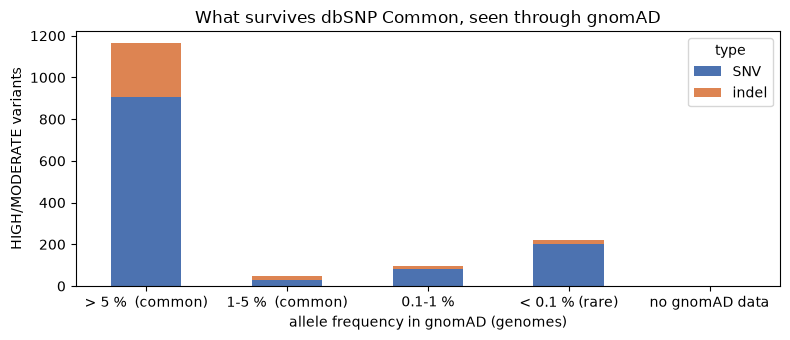

In [7]:
import matplotlib.pyplot as plt

ax = tab.drop(columns="total").plot.bar(stacked=True, figsize=(8, 3.5), color=["#4C72B0", "#DD8452"])
ax.set_ylabel("HIGH/MODERATE variants")
ax.set_xlabel("allele frequency in gnomAD (genomes)")
ax.set_title("What survives dbSNP Common, seen through gnomAD")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

We checked a sample of 300 of those common SNVs against the local dbSNP with `tabix`: **none was in the file**. This is not a key bug in `run_step2_prefilter.py`; the 2018 blacklist simply does not contain most of the coding variants gnomAD flags as common (including cases where the reference genome carries the minor allele, AF ≈ 0.9999). Indels are worse because dbSNP normalises them differently (278 of 307 are common).

**Consequence for the team:** the effective frequency filter is `GNOMAD_AF` from Step 3A. Step 5 discards AF > 1 % (`--max-af 0.01`, the same threshold the procedure justifies; it is not lowered because of the founder-effect caution in `00-references.md` §4). The structural fix would be to replace dbSNP Common with a gnomAD blacklist in Step 2.

### ClinVar: what it says about what is already reported

In [8]:
clin = a3.clinvar.dropna().str.split("|").explode().str.replace("_", " ").value_counts().to_frame("variants")
clin

,variants
clinvar,
Benign,182
Uncertain significance,96
Likely benign,65
Benign/Likely benign,17
Conflicting interpretations of pathogenicity,9
Pathogenic,8
Likely pathogenic,5
not provided,4
drug response,3


## 3B — AlphaGenome Atlas: AVI scoring

`step3b_alphagenome.py` asks the AlphaGenome Atlas for two *scorers* per variant:

* **`AVI_SCORE`**: AlphaGenome Variant Impact, a unified molecular-impact score. It comes with a quantile calibrated against all genome-wide SNVs; we convert it to **`AVI_PHRED` = −10·log10(1 − quantile)**, the same scale as CADD: ≥20 is the top 1 % of the genome, ≥30 the top 0.1 %.
* **`AVI_SCORE_FEATURE_IMPORTANCE`**: 18 modalities (splicing, AlphaMissense, Cactus/phastCons conservation, RNA-seq, DNase, …). We keep the one with the largest attribution in **`REGULATORY_FEATURE`**: it says *why* the model believes the variant matters.

Limitations discovered against the live API (alphagenome 0.9.0):

* **SNVs only.** Every indel returns `NotImplementedError`; the script marks them `AVI_STATUS=indel_unsupported` without spending a call.
* The server validates the REF allele against GRCh38 and one error fails the whole batch; the script retries variant by variant and marks `ref_mismatch`.
* `TARGET_GENE`, planned in the procedure, is not returned by these scorers: the gene remains snpEff's `GENE_SYMBOL`.
* It is a **research** tool: a high AVI is predicted molecular impact, not a diagnosis.

In [9]:
rows = []
for chrom, pos, ref, alt, info, sample in iter_vcf(STEP3B):
    rows.append({"gene": info.get("GENE_SYMBOL"), "impact": info.get("PUTATIVE_IMPACT"),
                 "status": info.get("AVI_STATUS"), "avi_phred": fnum(info.get("AVI_PHRED")),
                 "feature": info.get("REGULATORY_FEATURE")})
b3 = pd.DataFrame(rows)
print(f"Variants in the 3B output: {len(b3):,}")
print(b3.status.value_counts().to_string(), "\n")
scored = b3.dropna(subset=["avi_phred"])
print(f"AVI_PHRED >= 20 (genome-wide top 1 %): {int((scored.avi_phred>=20).sum())}   "
      f">= 30 (top 0.1 %): {int((scored.avi_phred>=30).sum())}")
pd.crosstab(b3.feature.fillna("(no score)"), b3.impact).sort_values("MODERATE", ascending=False)

Variants in the 3B output: 1,526
status
ok                   1220
indel_unsupported     306 

AVI_PHRED >= 20 (genome-wide top 1 %): 257   >= 30 (top 0.1 %): 13


impact,HIGH,MODERATE
feature,,
CACTUS_241_WAY,8,554
ALPHAMISSENSE,0,509
(no score),167,139
PHASTCONS_470_WAY,3,70
MERGED_SPLICING,2,43
MAX_ABS_DNASE,0,5
MAX_ABS_CHIP_HISTONE,0,2
MAX_ABS_RNA_SEQ,0,2
MAX_ABS_CAGE,1,0


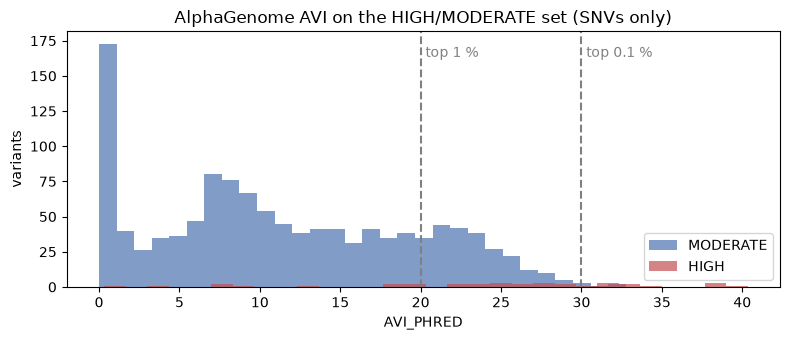

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for imp, color in (("MODERATE", "#4C72B0"), ("HIGH", "#C44E52")):
    ax.hist(scored.loc[scored.impact == imp, "avi_phred"], bins=30, alpha=0.7, label=imp, color=color)
for x, lab in ((20, "top 1 %"), (30, "top 0.1 %")):
    ax.axvline(x, ls="--", color="grey"); ax.text(x + 0.3, ax.get_ylim()[1] * 0.9, lab, color="grey")
ax.set_xlabel("AVI_PHRED"); ax.set_ylabel("variants"); ax.set_title("AlphaGenome AVI on the HIGH/MODERATE set (SNVs only)")
ax.legend(); plt.tight_layout(); plt.show()

Reading: the dominant modality for coding variants is **conservation** (`CACTUS_241_WAY`) followed by **AlphaMissense**; splicing and protein termination appear in the HIGH set. Because AVI and CADD share the Phred scale, Step 5 can use them together as in-silico evidence.

## Gene-level check of the MVA panel

`docs/00-references.md` §2 defines the panel: *BUB1B* (MVA1), *CEP57* (MVA2), *TRIP13* (MVA3), *MAD2L1BP*. Before any prioritisation we look at whether any of them carries rare protein-altering variants. The table shows **gene, type and annotations**, without coordinates: by repo rule (`CLAUDE.md`) patient coordinates are not committed; they live in the gitignored VCF.

In [11]:
PANEL = ["BUB1B", "CEP57", "TRIP13", "MAD2L1BP"]
panel_rows = []
for chrom, pos, ref, alt, info, sample in iter_vcf(STEP3B):
    g = info.get("GENE_SYMBOL")
    if g in PANEL:
        panel_rows.append({
            "gene": g, "consequence": info.get("CONSEQUENCE"), "impact": info.get("PUTATIVE_IMPACT"),
            "zygosity": zygosity(sample), "AB": fnum(info.get("AB_FILTER")),
            "gnomAD_AF": fnum(info.get("GNOMAD_AF")), "CADD": fnum(info.get("CADD_PHRED")), "REVEL": fnum(info.get("REVEL")),
            "AVI_PHRED": fnum(info.get("AVI_PHRED")), "AVI_feature": info.get("REGULATORY_FEATURE"),
            "ClinVar": (info.get("CLINVAR_SIG") or "-").replace("_", " "), "OMIM": info.get("OMIM_PHENOTYPE") or "-",
        })
panel = pd.DataFrame(panel_rows)
for g in PANEL:
    if g not in set(panel.gene):
        print(f"{g}: no rare HIGH/MODERATE variants")
panel

CEP57: no rare HIGH/MODERATE variants
TRIP13: no rare HIGH/MODERATE variants
MAD2L1BP: no rare HIGH/MODERATE variants


,gene,consequence,impact,zygosity,AB,gnomAD_AF,CADD,REVEL,AVI_PHRED,AVI_feature,ClinVar,OMIM
0,BUB1B,stop_gained,HIGH,HET,0.543,0.000033,36.0,NaN,33.76,PROTEIN_TERMINATION,Pathogenic|Likely pathogenic,257300
1,BUB1B,missense_variant,MODERATE,HET,0.464,NaN,24.5,0.472,25.61,ALPHAMISSENSE,-,-


Reading (research annotation, not a clinical statement): the only panel gene with rare protein-altering variants is ***BUB1B*, with two heterozygous variants**: a stop-gain already classified Pathogenic/Likely pathogenic in ClinVar for MVA1 (OMIM 257300), and a missense absent from gnomAD with CADD, REVEL and AVI in the suggestive range. Two heterozygous variants in an autosomal-recessive gene is exactly the compound-heterozygous pattern described for MVA1 in the references. Phase (whether they sit on different chromosomes) cannot be determined from a single-sample VCF.

### Figure: the two *BUB1B* variants explained for non-specialists

Interactive version with an English/Español switch at the top right: [`docs/figures/bub1b_variants_explained.html`](../../docs/figures/bub1b_variants_explained.html) (regenerate with `python docs/figures/build_bub1b_figure.py`).

Gene map (chromosome 15 → 23 exons → changes in exons 17 and 23), letter-level zoom with reference-genome neighbours, and an explanation of heterozygosity with the two possible phase scenarios. Change 1 turns the TTA triplet (leucine) into TGA, a STOP signal: the protein is cut short at brick 751 of 1064. Change 2 turns AAT (asparagine) into AAG (lysine): the protein is completed with a different piece. Each change shows up in half of the reads, so it sits on only one of the two gene copies (heterozygous); with one person's DNA alone we cannot tell whether they are on different copies (compound heterozygosity, the MVA type 1 pattern) or on the same one.

![The two BUB1B variants, explained](../../docs/figures/bub1b_variants_explained_en.png)

## Summary: from 5 million variants to 2 candidates, and why those remained

Every pipeline step applies **one criterion with a biological rationale**, and most of the reduction happens in two places: the common-variant subtraction (Step 2) and the protein-impact filter (Step 3A). The table below is computed from the output files; the first two numbers come from the `run_step2_prefilter.py` log (5,012,204 read, 4,428,273 after QC).

| Stage | Criterion | Why |
|---|---|---|
| **Raw VCF** | everything the sequencer called | starting point: ~5 M differences from the reference genome |
| **Intrinsic QC** (Step 2) | `FILTER` PASS or empty, GQ ≥ 20, DP ≥ 10, allelic balance 0.30–0.70 for hets | drops calls the sequencer itself is unsure about (low coverage, read bias) — see `01-procedure.md` Step 2 |
| **Not common in dbSNP** (Step 2) | no exact chrom:pos:ref:alt match in dbSNP Common (MAF ≥ 1 %) | an ultra-rare disease cannot be caused by a variant carried by 1 % of the population; 1 % and not lower because of the founder-effect caution (`00-references.md` §4) |
| **Alters the protein** (Step 3A) | snpEff impact `HIGH` or `MODERATE` on the canonical transcript | ~85 % of known pathogenic Mendelian variants sit in exons or splice sites (`00-references.md` §3); the remaining 99.5 % is intronic/intergenic and not interpretable today |
| **Rare in gnomAD** (3A annotation) | AF ≤ 1 % in gnomAD genomes, or absent | fixes the dbSNP Common gap: 1,212 of the 1,526 protein-altering variants turned out to be common in gnomAD |
| **MVA panel gene** (targeted check) | *BUB1B*, *CEP57*, *TRIP13*, *MAD2L1BP* | genes already proven to cause MVA (`00-references.md` §2); the first place to look, not the only one |

The last row **is not a pipeline filter**: it is the explicit check the procedure asks for. Formal phenotype-based prioritisation (HPO) is Step 4, which has not yet been run on these data.

In [12]:
# Reduction funnel. The first two values come from the run_step2_prefilter.py log (2026-09-17).
RAW, QC = 5_012_204, 4_428_273
n_step2 = sum(1 for _ in iter_vcf(STEP2))                       # survive dbSNP Common
n_coding = len(a3)                                              # HIGH/MODERATE (Step 3A)
rare_gnomad = a3[a3.gnomad_af.fillna(0) <= 0.01]                # AF <= 1 % or no data (= absent from gnomAD)
n_rare = len(rare_gnomad)
n_panel = int(len(panel))

funnel = pd.DataFrame({"variants": [RAW, QC, n_step2, n_coding, n_rare, n_panel]},
    index=["Raw VCF", "Intrinsic QC (Step 2)", "Not common in dbSNP (Step 2)",
           "Alters the protein: HIGH/MODERATE (Step 3A)", "Rare in gnomAD, AF ≤ 1 % (3A annotation)",
           "In an MVA panel gene (targeted check)"])
funnel["% of raw"] = (funnel.variants / RAW * 100).round(3)
funnel["dropped at this stage"] = (funnel.variants.shift(1) - funnel.variants).fillna(0).astype(int)
funnel

,variants,% of raw,dropped at this stage
Raw VCF,5012204,100.000,0
Intrinsic QC (Step 2),4428273,88.350,583931
Not common in dbSNP (Step 2),591339,11.798,3836934
Alters the protein: HIGH/MODERATE (Step 3A),1526,0.030,589813
"Rare in gnomAD, AF ≤ 1 % (3A annotation)",314,0.006,1212
In an MVA panel gene (targeted check),2,0.000,312


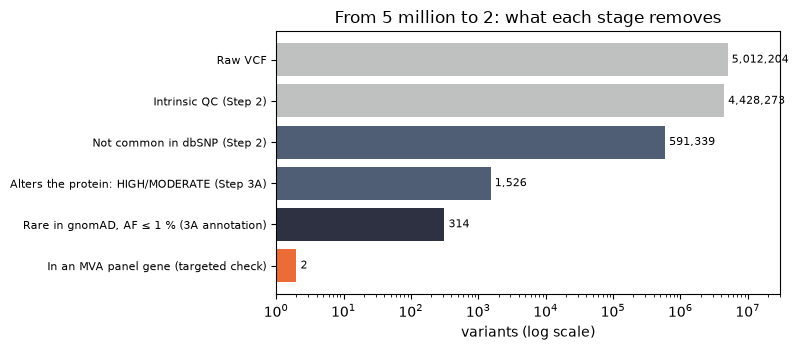

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.6))
vals = funnel.variants.values
ypos = list(range(len(vals)))[::-1]
ax.barh(ypos, vals, color=["#bfc0c0", "#bfc0c0", "#4f5d75", "#4f5d75", "#2d3142", "#eb6c36"])
ax.set_xscale("log"); ax.set_xlim(1, 3e7)
ax.set_yticks(ypos); ax.set_yticklabels(funnel.index, fontsize=8)
for y, v in zip(ypos, vals):
    ax.text(v * 1.15, y, f"{v:,}", va="center", fontsize=8)
ax.set_xlabel("variants (log scale)"); ax.set_title("From 5 million to 2: what each stage removes")
plt.tight_layout(); plt.show()

### Why exactly these two remained

The variants that pass every automatic filter (the "rare in gnomAD" row) are **legitimate candidates**; Step 4 will rank them by how much each gene explains the clinical picture. That the two *BUB1B* variants already stand out here comes from four independent facts converging on the same gene:

1. **It is a known causal gene for MVA.** *BUB1B* encodes BubR1, a component of the checkpoint that ensures chromosomes are distributed correctly during cell division; its failure produces exactly the mosaic aneuploidy that defines the disease (`00-references.md` §2).
2. **There are two variants, not one, and both are heterozygous.** MVA type 1 is autosomal recessive: both copies must be damaged. Two heterozygous variants in the same gene is the signature of compound heterozygosity. Phase (whether they are on different copies) cannot be confirmed from the patient's DNA alone.
3. **One is already classified.** The exon-17 variant creates a premature STOP and is listed in ClinVar as Pathogenic / Likely pathogenic for MVA type 1 (OMIM 257300), with a population frequency of ~3 per 100,000.
4. **The other is rare and the predictors agree.** The exon-23 missense is absent from gnomAD, and CADD (24.5), REVEL (0.47) and AlphaGenome (AVI_PHRED 25.6, AlphaMissense modality) place it among the variants with the highest predicted impact.

No other panel gene (*CEP57*, *TRIP13*, *MAD2L1BP*) carries rare protein-altering variants. This is a **research annotation**, not a diagnosis: confirmation requires phase (parental DNA) and clinical validation.

## What comes next

* **Step 4** (`track1_step4_prioritize.py`): HPO semantic similarity per gene + biallelic evidence + panel check. Implemented and tested; **not yet run on the real data** by team decision.
* **Step 5** (`track1_step5_submission.py`): `epcr` score and submission CSV with enforced separation between rows (F-max penalises ties). Includes the gnomAD AF ≤ 1 % filter.
* Open for discussion: replacing dbSNP Common with gnomAD in Step 2.